In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay


df = pd.read_csv('../data/bank_clean.csv')
df['y_numeric'] = df['y'].map({'yes': 1, 'no': 0})

print("Data loaded and ready for ML ")

Data loaded and ready for ML ✅


In [22]:
df['age_group'] = pd.cut(df['age'], bins =[17,30,40,50,60,100] , labels = ['18-30','30-40','40-50','50-60','+60'])
df['was_contacted_before'] = (df['pdays']!= -1).astype(int)
df['campaign_intensity'] = pd.cut(df['campaign'] , bins=[1,5,10,15,20,100] , labels =['1-5','5-10','10-15','15-20','+20'])
df['previous_success'] = (df['poutcome'] == 'success').astype(int)

df_encoded = pd.get_dummies(df, drop_first= True )
print('New shape:', df_encoded.shape)

New shape: (45211, 54)


In [23]:
df_encoded.head()

,age,balance,day,duration,campaign,pdays,previous,y_numeric,was_contacted_before,previous_success,...,poutcome_unknown,y_yes,age_group_30-40,age_group_40-50,age_group_50-60,age_group_+60,campaign_intensity_5-10,campaign_intensity_10-15,campaign_intensity_15-20,campaign_intensity_+20
0,58,2143,5,261,1,-1,0,0,0,0,...,True,False,False,False,True,False,False,False,False,False
1,44,29,5,151,1,-1,0,0,0,0,...,True,False,False,True,False,False,False,False,False,False
2,33,2,5,76,1,-1,0,0,0,0,...,True,False,True,False,False,False,False,False,False,False
3,47,1506,5,92,1,-1,0,0,0,0,...,True,False,False,True,False,False,False,False,False,False
4,33,1,5,198,1,-1,0,0,0,0,...,True,False,True,False,False,False,False,False,False,False


In [24]:
# separate the features (X) and the target (y)
y=df_encoded['y_yes']
x= df_encoded.drop(columns =['y_yes','y_numeric'] , errors= 'ignore')
print("Shape of X:", x.shape)
print("Shape of y:", y.shape)

Shape of X: (45211, 52)
Shape of y: (45211,)


In [25]:
# split the data into train (80%) and test (20%) 
X_train, X_test, y_train, y_test = train_test_split(x,y,test_size = 0.2 , random_state= 42 , stratify=y)
print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)

Train shape: (36168, 52)
Test shape: (9043, 52)


In [26]:

scaler = StandardScaler()
cols_to_scale = ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']
X_train_scaled = X_train.copy() 
X_train_scaled[cols_to_scale] = scaler.fit_transform(X_train[cols_to_scale])
X_test_scaled = X_test.copy()
X_test_scaled[cols_to_scale] = scaler.transform(X_test[cols_to_scale])

print("Data scaled successfully ")
print("Mean of 'age' in train:", X_train_scaled['age'].mean().round(2))
print("Std of 'age' in train:", X_train_scaled['age'].std().round(2))

Data scaled successfully 
Mean of 'age' in train: -0.0
Std of 'age' in train: 1.0


In [27]:
# Model 1 — Logistic Regression

log_reg = LogisticRegression(max_iter=1000, random_state=42)

log_reg.fit(X_train_scaled, y_train)

y_pred_log = log_reg.predict(X_test_scaled)

print("Logistic Regression model trained")
print(classification_report(y_test, y_pred_log))

Logistic Regression model trained
              precision    recall  f1-score   support

       False       0.92      0.97      0.95      7985
        True       0.65      0.36      0.46      1058

    accuracy                           0.90      9043
   macro avg       0.78      0.67      0.70      9043
weighted avg       0.89      0.90      0.89      9043



Logistic Regression Results

**Accuracy:** 90% (Misleading due to class imbalance)
**Recall (True):** 36% (Very low - the model misses 64% of potential subscribers)
**Precision (True):** 65%

**Conclusion:** The Logistic Regression model is too conservative. Because the dataset is highly imbalanced (88% "no"), the model struggles to identify the "yes" class. We need to try other models (Decision Tree, Random Forest) or adjust class weights.

In [28]:
#  Model 2 — Decision Tree
tree =DecisionTreeClassifier(max_depth= 10, random_state=42)
tree.fit(X_train_scaled ,y_train)
y_pred_tree = tree.predict(X_test_scaled)
print("Decision tree model trained")
print(classification_report(y_test, y_pred_tree))

Decision tree model trained
              precision    recall  f1-score   support

       False       0.92      0.97      0.94      7985
        True       0.61      0.40      0.48      1058

    accuracy                           0.90      9043
   macro avg       0.77      0.68      0.71      9043
weighted avg       0.89      0.90      0.89      9043



In [29]:
# Model 3 — Random Forest: 
rf = RandomForestClassifier(random_state=42)
rf.fit(X_train_scaled, y_train)
y_pred_rf = rf.predict(X_test_scaled)

print("Random Forest model trained")
print(classification_report(y_test, y_pred_rf))

Random Forest model trained
              precision    recall  f1-score   support

       False       0.92      0.98      0.95      7985
        True       0.68      0.39      0.49      1058

    accuracy                           0.91      9043
   macro avg       0.80      0.68      0.72      9043
weighted avg       0.90      0.91      0.90      9043



Random Forest Results

**Accuracy:** 91% (Highest accuracy so far)
**Recall (True):** 39%
**Precision (True):** 68%

**Conclusion:** The Random Forest has the best precision and accuracy. However, like the other models, its Recall for the "yes" class remains low (39%) due to the highly imbalanced dataset (88% "no"). The model is too conservative and misses 61% of potential subscribers.


# Which model is the best?

Based on the evaluation metrics, the **Random Forest** is the best model overall.
- It has the highest **Accuracy** (91%).
- It has the highest **Precision** (68%) for the "yes" class, meaning it makes fewer false positive errors.
- Although the Decision Tree has a slightly higher Recall (40% vs 39%), the Random Forest is more robust and generalizes better (no overfitting).

**Conclusion:** We will select the Random Forest model for the final business analysis.

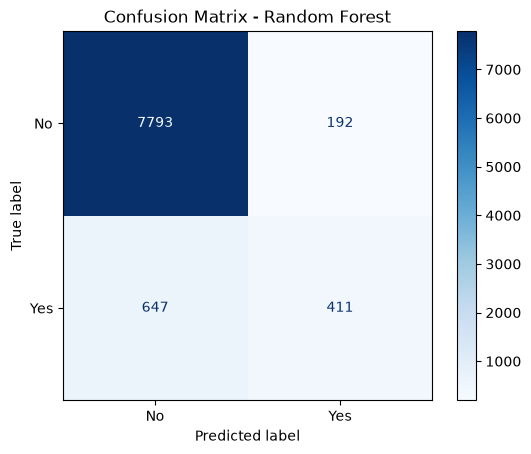

In [30]:
# the confusion matrix of the best model. How many false positives? How many false negatives? 
cm = confusion_matrix(y_test, y_pred_rf)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No', 'Yes'])
disp.plot(cmap='Blues')
plt.title("Confusion Matrix - Random Forest")
plt.show()

Confusion Matrix Analysis

**True Negatives (TN):** 7,793 (Correctly predicted "No")

**True Positives (TP):** 411 (Correctly predicted "Yes")

**False Positives (FP):** 192 (Predicted "Yes", but actually "No")

**False Negatives (FN):** 647 (Predicted "No", but actually "Yes")

**Business Impact:** The model misses 647 potential subscribers (False Negatives). This is the most costly error for the bank. We need to find a way to reduce these False Negatives, even if it means increasing False Positives (calling more people).

C:\Users\DELL\AppData\Local\Temp\ipykernel_10472\588129429.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=feature_importance_df, palette='viridis')


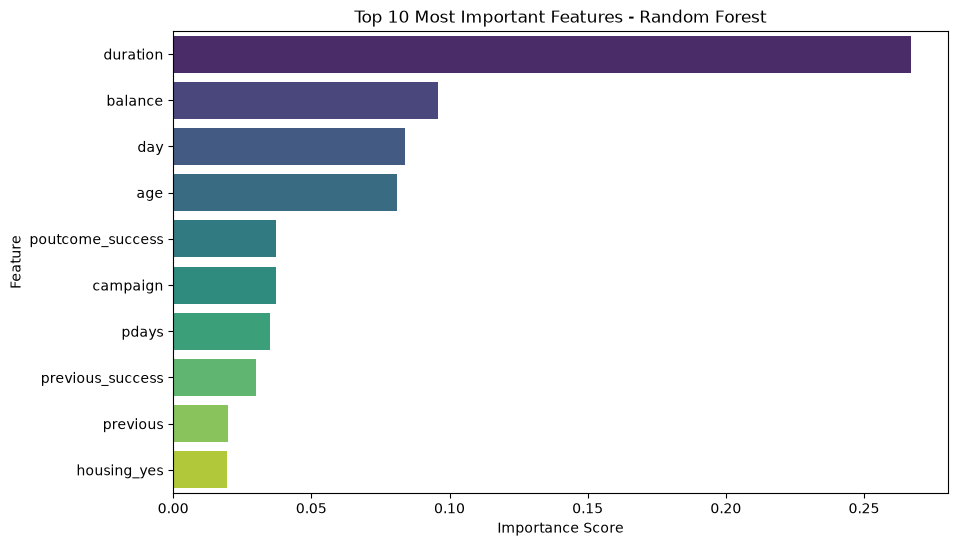

In [32]:

importances = rf.feature_importances_
feature_importance_df = pd.DataFrame({
    'Feature': x.columns,
    'Importance': importances
}).sort_values(by='Importance', ascending=False).head(10) # Top 10
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feature_importance_df, palette='viridis')
plt.title("Top 10 Most Important Features - Random Forest")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.show()

Top 5 Most Important Features

According to the Random Forest model, the top 5 most important features for predicting subscription are:
1. **Duration:** (Most important by far) The longer the call, the higher the chance of subscription.
2. **Balance:** Clients with higher bank balances are more likely to subscribe.
3. **Day:** The day of the month of the call has an unexpected impact.
4. **Age:** The client's age influences the decision.
5. **Poutcome_success:** A successful previous campaign is a very strong signal.

**Business Insight:** These features confirm our EDA findings. Sales agents should focus on keeping clients on the phone longer and target wealthy clients who had a positive past experience.

## Why is accuracy alone misleading on this dataset?

**Answer:** 
The dataset is highly **imbalanced** (88.3% "no" vs 11.7% "yes"). 

If we evaluate a model only with Accuracy, a "lazy" model that always predicts "no" would achieve an accuracy of 88%, even though it is completely useless for the bank. It would never identify a single potential subscriber (Recall = 0%).

**Conclusion:** On an imbalanced dataset, Accuracy is misleading. We must rely on other metrics like **Recall** (to catch the "yes" class), **Precision** (to avoid calling too many people for nothing), and the **F1-Score** (a balance between both). This is why we focused on the Recall of the "True" class in our evaluation.
